## Credit Card Fraud Detection using Machine Learning & SMOTE

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df['Class'].unique()

array([0, 1])

In [4]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

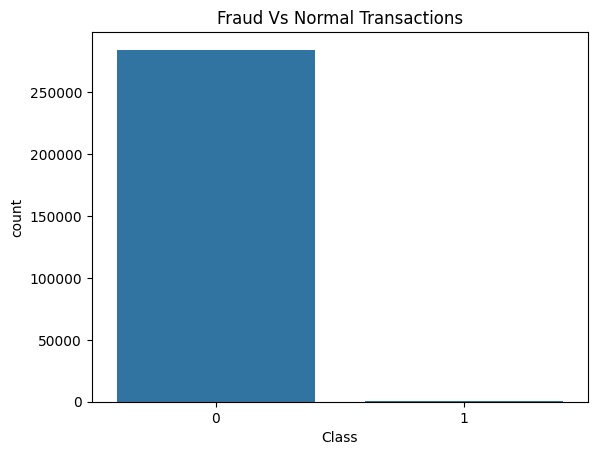

In [5]:
plt.figure()
sns.countplot(x='Class',data=df)
plt.title('Fraud Vs Normal Transactions')
plt.show()

In the above graph the Normal Transactions are indicated as '0' whereas the Fraud transactions are detected as '1'<br>
The graph shows that normal transactions are much higher than fraud transactions, which means the dataset is highly imbalanced.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, precision_recall_curve,
                             average_precision_score)
from imblearn.over_sampling import SMOTE


In [13]:
# Split, scale, then apply SMOTE to the training set only.
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)

scaler = StandardScaler()
Xs_tr = scaler.fit_transform(X_tr)
Xs_val = scaler.transform(X_val)
Xs_test = scaler.transform(X_test)

Xs_tr_sm, y_tr_sm = SMOTE(random_state=42).fit_resample(Xs_tr, y_tr)

In [8]:
lr = LogisticRegression(max_iter=3000)
lr.fit(Xs_tr, y_tr)

lr_smote = LogisticRegression(max_iter=3000)
lr_smote.fit(Xs_tr_sm, y_tr_sm)

rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=2,
                            class_weight='balanced_subsample',
                            n_jobs=-1, random_state=42)
rf.fit(Xs_tr, y_tr)

models = {"Logistic Regression": lr,
          "Logistic + SMOTE": lr_smote,
          "Random Forest": rf}

In [9]:
for name, m in models.items():
    prob = m.predict_proba(Xs_test)[:, 1]
    print(name, "| PR-AUC:", round(average_precision_score(y_test, prob), 3))
    print(classification_report(y_test, m.predict(Xs_test), digits=3))

Logistic Regression | PR-AUC: 0.745
              precision    recall  f1-score   support

           0      0.999     1.000     1.000     56864
           1      0.829     0.643     0.724        98

    accuracy                          0.999     56962
   macro avg      0.914     0.821     0.862     56962
weighted avg      0.999     0.999     0.999     56962

Logistic + SMOTE | PR-AUC: 0.724
              precision    recall  f1-score   support

           0      1.000     0.975     0.987     56864
           1      0.058     0.898     0.108        98

    accuracy                          0.975     56962
   macro avg      0.529     0.936     0.548     56962
weighted avg      0.998     0.975     0.986     56962

Random Forest | PR-AUC: 0.851
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56864
           1      0.961     0.745     0.839        98

    accuracy                          1.000     56962
   macro avg      0.980     0

In [10]:
def pick_threshold(model, min_recall=0.80):
    prob = model.predict_proba(Xs_val)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_val, prob)
    ok = recall[:-1] >= min_recall
    i = np.argmax(np.where(ok, precision[:-1], -1))
    return thresholds[i]

y_true = y_test.values
rows = []
for name, m in models.items():
    t = pick_threshold(m)
    prob = m.predict_proba(Xs_test)[:, 1]
    pred = (prob >= t).astype(int)
    tp = ((pred == 1) & (y_true == 1)).sum()
    fp = ((pred == 1) & (y_true == 0)).sum()
    fn = ((pred == 0) & (y_true == 1)).sum()
    rows.append({"Model": name, "Threshold": round(t, 3),
                 "Precision": round(tp / (tp + fp), 3),
                 "Recall": round(tp / (tp + fn), 3),
                 "False alarms": fp,
                 "PR-AUC": round(average_precision_score(y_true, prob), 3)})

pd.DataFrame(rows)

,Model,Threshold,Precision,Recall,False alarms,PR-AUC
0,Logistic Regression,0.026,0.606,0.847,54,0.745
1,Logistic + SMOTE,0.992,0.483,0.878,92,0.724
2,Random Forest,0.120,0.708,0.867,35,0.851


##### Model Evaluation and Conclusion

**Evaluation approach.** Fraud accounts for only 0.17% of transactions, so accuracy is not informative: a model that labels every transaction as legitimate would score about 99.8%. Models were compared on precision, recall and PR-AUC for the fraud class. The decision threshold was tuned on a separate validation set, and the held-out test set (56,962 transactions, 98 of them fraud) was used only for the final comparison.

**Results at the default threshold (0.5).**
- Logistic Regression: precision 0.83, recall 0.64.
- Logistic Regression with SMOTE: recall rose to 0.90, but precision fell to 0.06, which means about 1,400 legitimate transactions were flagged as fraud.
- Random Forest: precision 0.96, recall 0.75.

**Results after threshold tuning (minimum recall of 0.80 on the validation set).**

| Model | Precision | Recall | False alarms | PR-AUC |
|---|---|---|---|---|
| Logistic Regression | 0.61 | 0.85 | 54 | 0.745 |
| Logistic Regression + SMOTE | 0.48 | 0.88 | 92 | 0.724 |
| Random Forest | 0.71 | 0.87 | 35 | 0.851 |

**Findings.**
- SMOTE rebalances the training data only, and it raised recall at the default threshold. After tuning, however, all three models reached similar recall (0.85 to 0.88), and SMOTE gave no clear benefit. It produced the lowest precision and the lowest PR-AUC.
- Threshold selection had a larger effect than resampling. Most of the false alarms in the original model came from the default cutoff, not from the model itself.
- The Random Forest achieved the highest PR-AUC and the best precision at comparable recall, with 35 false alarms among 56,864 legitimate transactions. It is the selected model.

**Limitations.**
- The test set contains only 98 fraud cases, so differences in recall of a few percentage points correspond to a handful of transactions.
- Results come from a single train-validation-test split and were not cross-validated.
- The threshold depends on the chosen recall target. In practice it should be set from the relative cost of a missed fraud versus a false alarm.

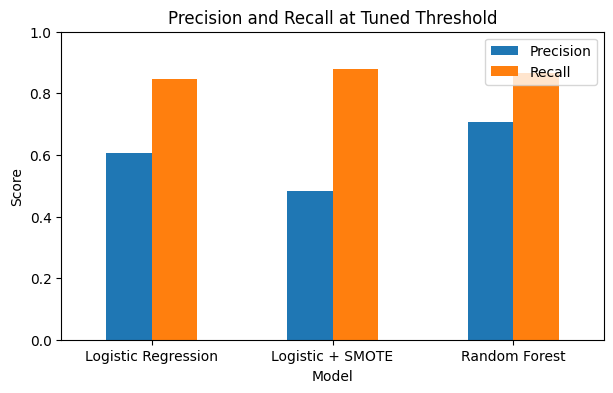

In [12]:
results = pd.DataFrame(rows).set_index("Model")
results[["Precision", "Recall"]].plot(kind="bar", figsize=(7, 4), rot=0)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Precision and Recall at Tuned Threshold")
plt.show()

Recall is similar across the three models after threshold tuning, so precision is what separates them. The Random Forest has the highest precision.